# Day 84: Project 3 — Customer Segmentation: EDA + Clustering

## Objective
- Load and inspect the Mall Customers data, and check its quality before any model
- EDA: histogram + boxplot for Age, Annual Income and Spending Score, and how the columns relate
- Scale the numeric features with `StandardScaler` (always before K-Means) and see what scaling changes
- Elbow method: K-Means for K = 2 to 10, plot the inertia, and read the bend
- Cross-check the elbow, because it is a judgment call, and choose a K to carry into Day 85

> **Data:** the Mall Customers sample dataset (200 customers). The file is not included in this folder.
> The notebook uses `data/` if it is there, otherwise it downloads a public copy. See `data/README.md`.

> **Plan for Project 3:** Day 84 prepares the data and picks K. Day 85 fits K-Means, draws the PCA picture and profiles each cluster.
> Today I only use clustering to choose K. There are no cluster names and no business stories yet, because I have not looked at the clusters themselves.

## Imports

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter
from pathlib import Path

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score

from segmentation_data import load_mall, scale_numeric, NUMERIC

plt.style.use("seaborn-v0_8-darkgrid")
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
                     "axes.titlesize": 14, "axes.titleweight": "bold", "axes.labelsize": 11})
BLUE, ORANGE, GREEN, GOLD, GREY = "#0072B2", "#D55E00", "#009E73", "#E69F00", "#7F7F7F"
Path("images").mkdir(exist_ok=True)

## Theory
- **Clustering** is unsupervised: there is no target column. We look for groups of similar customers, and nobody tells us the right answer
- **K-Means** picks K centers, puts every customer with its nearest center, moves each center to the middle of its group, and repeats
- **Distance decides everything**, so a column measured in big numbers can drown out the others. That is why we scale first (Days 56 and 65)
- **Inertia** = the total squared distance from every customer to its own center. More clusters always lower it, so it never "finds" K by itself
- **Elbow method:** plot inertia against K and look for the bend, where adding a cluster stops paying off much
- **Silhouette score** (-1 to 1) says how well separated the clusters are. I use it as a second opinion on the elbow
- **Random starts:** K-Means starts from random centers and can land on a poor solution. `n_init=10` runs 10 starts and keeps the best one

## 1. Load and inspect

In [2]:
df = load_mall()                     # data/ if the file is there, otherwise a public download
print("Shape:", df.shape)
print()
print(df.head())
print()
df.info()

Shape: (200, 5)

   CustomerID  Gender  Age  Income  Spending
0           1    Male   19      15        39
1           2    Male   21      15        81
2           3  Female   20      16         6
3           4  Female   23      16        77
4           5  Female   31      17        40

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   CustomerID  200 non-null    int64
 1   Gender      200 non-null    str  
 2   Age         200 non-null    int64
 3   Income      200 non-null    int64
 4   Spending    200 non-null    int64
dtypes: int64(4), str(1)
memory usage: 7.9 KB


## 2. Data quality checks

In [3]:
checks = {
    "missing values (all cells)": int(df.isna().sum().sum()),
    "fully duplicated rows": int(df.duplicated().sum()),
    "repeated CustomerID": int(df["CustomerID"].duplicated().sum()),
    "Age outside 18 to 100": int(((df["Age"] < 18) | (df["Age"] > 100)).sum()),
    "Income <= 0": int((df["Income"] <= 0).sum()),
    "Spending outside 1 to 100": int(((df["Spending"] < 1) | (df["Spending"] > 100)).sum()),
}
print(pd.Series(checks).to_string())
print()
print("Gender counts:")
print(df["Gender"].value_counts().to_string())
print()
print(df[NUMERIC].describe().round(2).to_string())

missing values (all cells)    0
fully duplicated rows         0
repeated CustomerID           0
Age outside 18 to 100         0
Income <= 0                   0
Spending outside 1 to 100     0

Gender counts:
Gender
Female    112
Male       88

          Age  Income  Spending
count  200.00  200.00    200.00
mean    38.85   60.56     50.20
std     13.97   26.26     25.82
min     18.00   15.00      1.00
25%     28.75   41.50     34.75
50%     36.00   61.50     50.00
75%     49.00   78.00     73.00
max     70.00  137.00     99.00


The data is clean: nothing missing, no duplicates, and every value is in a believable range.
`Gender` is a label (two values), not a number, so it will not go into K-Means. I check below whether it would even help.
The "Spending Score" is a score the mall assigned from 1 to 100, not an amount of money.

## 3. EDA: one column at a time (histogram + boxplot)

In [4]:
def iqr_outliers(series):
    q1, q3 = series.quantile([0.25, 0.75])
    fence_low, fence_high = q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)
    return series[(series < fence_low) | (series > fence_high)]

rows = []
for col in NUMERIC:
    out = iqr_outliers(df[col])
    rows.append({"column": col, "mean": df[col].mean(), "median": df[col].median(),
                 "std": df[col].std(), "skew": df[col].skew(), "IQR outliers": len(out)})
print(pd.DataFrame(rows).round(2).to_string(index=False))

income_out = iqr_outliers(df["Income"])
print("\nIncome outliers (IQR rule):", income_out.tolist(), "-> CustomerID", df.loc[income_out.index, "CustomerID"].tolist())

  column  mean  median   std  skew  IQR outliers
     Age 38.85    36.0 13.97  0.49             0
  Income 60.56    61.5 26.26  0.32             2
Spending 50.20    50.0 25.82 -0.05             0

Income outliers (IQR rule): [137, 137] -> CustomerID [199, 200]


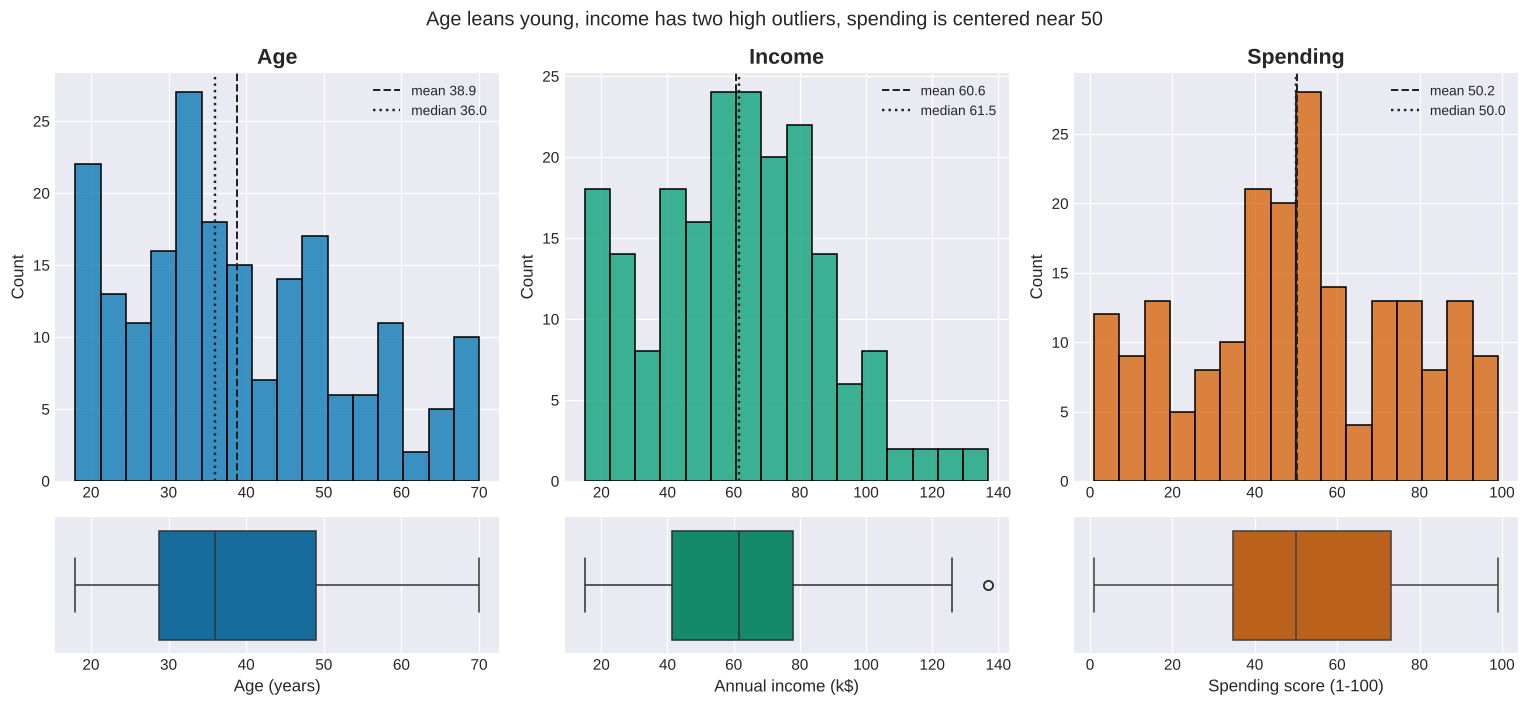

In [5]:
fig, axes = plt.subplots(2, 3, figsize=(14, 6.5), gridspec_kw={"height_ratios": [3, 1]})
colors = [BLUE, GREEN, ORANGE]
for i, (col, color) in enumerate(zip(NUMERIC, colors)):
    sns.histplot(df[col], bins=16, color=color, ax=axes[0, i])
    axes[0, i].axvline(df[col].mean(), color="#222222", linestyle="--", linewidth=1.3, label=f"mean {df[col].mean():.1f}")
    axes[0, i].axvline(df[col].median(), color="#222222", linestyle=":", linewidth=1.6, label=f"median {df[col].median():.1f}")
    axes[0, i].set_title(col)
    axes[0, i].set_xlabel("")
    axes[0, i].legend(fontsize=9)
    sns.boxplot(x=df[col], color=color, ax=axes[1, i])
    axes[1, i].set_xlabel({"Age": "Age (years)", "Income": "Annual income (k$)", "Spending": "Spending score (1-100)"}[col])
plt.suptitle("Age leans young, income has two high outliers, spending is centered near 50", fontsize=13)
plt.tight_layout()
plt.savefig("images/distributions_hist_box.png")
plt.show()

- **Age** runs from 18 to 70 with a mild right lean (more people in their 20s and 30s)
- **Income** is fairly symmetric, with two customers at 137k that the boxplot marks as outliers. Only two out of 200, so I keep them
- **Spending score** covers the whole range from 1 to 99, with a peak around 40 to 60 and wide tails (skew near zero)
- No column needs a transform. The ranges are different, which is the reason to scale (section 5)

## 4. EDA: how the columns relate

In [6]:
print("Correlation (Pearson):")
print(df[NUMERIC].corr().round(3).to_string())
print()
print("Average by Gender:")
print(df.groupby("Gender")[NUMERIC].mean().round(1).to_string())

Correlation (Pearson):
            Age  Income  Spending
Age       1.000  -0.012    -0.327
Income   -0.012   1.000     0.010
Spending -0.327   0.010     1.000

Average by Gender:
         Age  Income  Spending
Gender                        
Female  38.1    59.2      51.5
Male    39.8    62.2      48.5


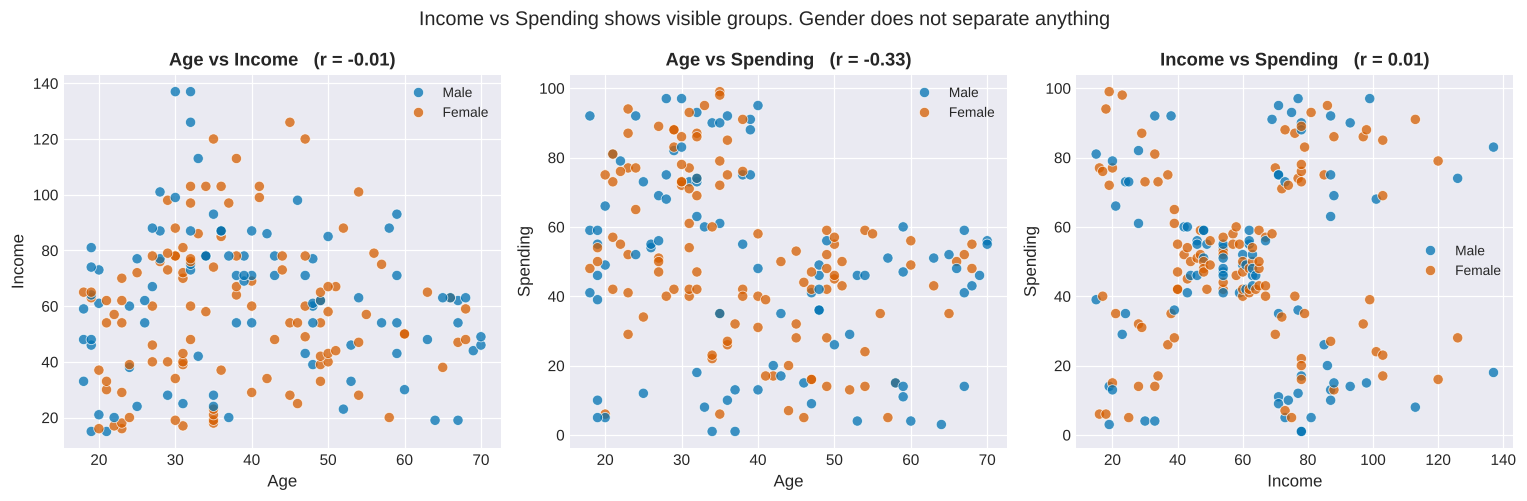

In [7]:
pairs = [("Age", "Income"), ("Age", "Spending"), ("Income", "Spending")]
fig, axes = plt.subplots(1, 3, figsize=(14, 4.6))
for ax, (a, b) in zip(axes, pairs):
    sns.scatterplot(data=df, x=a, y=b, hue="Gender", palette={"Female": ORANGE, "Male": BLUE}, alpha=0.75, s=45, ax=ax)
    ax.set_title(f"{a} vs {b}   (r = {df[a].corr(df[b]):.2f})", fontsize=12)
    ax.legend(title="", fontsize=9, loc="best")
plt.suptitle("Income vs Spending shows visible groups. Gender does not separate anything", fontsize=13)
plt.tight_layout()
plt.savefig("images/relationships_scatter.png")
plt.show()

- **Age and Spending** have a moderate negative link (r = -0.33): younger customers tend to have higher spending scores
- **Income** is unrelated to age and to spending (r near 0), so income alone says nothing about spending
- The **Income vs Spending** scatter has visible clumps. That is a hint that clusters exist, not a result: I have not fitted anything yet
- The two Gender colors are mixed together in every plot

## 5. Scale the numeric features

In [8]:
X_scaled, scaler = scale_numeric(df)          # StandardScaler on Age, Income, Spending (all 200 customers)

before = df[NUMERIC].agg(["mean", "std"]).T
after = pd.DataFrame(X_scaled, columns=NUMERIC).agg(["mean", "std"]).T
after["std"] = pd.DataFrame(X_scaled, columns=NUMERIC).std(ddof=0)      # StandardScaler divides by the population std
print("Before scaling:")
print(before.round(2).to_string())
print("\nAfter scaling (mean 0, std 1):")
print(after.round(2).to_string())

Before scaling:
           mean    std
Age       38.85  13.97
Income    60.56  26.26
Spending  50.20  25.82

After scaling (mean 0, std 1):
          mean  std
Age       -0.0  1.0
Income    -0.0  1.0
Spending  -0.0  1.0


In [9]:
# Does scaling change the answer on THIS data? Cluster with and without it (K = 5) and compare the groups.
labels_scaled = KMeans(n_clusters=5, init="k-means++", n_init=10, random_state=42).fit_predict(X_scaled)
labels_raw = KMeans(n_clusters=5, init="k-means++", n_init=10, random_state=42).fit_predict(df[NUMERIC].to_numpy())

ari = adjusted_rand_score(labels_scaled, labels_raw)
print("Raw standard deviations:", df[NUMERIC].std().round(1).to_dict())
print(f"Agreement between the scaled and unscaled groupings (adjusted Rand index): {ari:.2f}")
print("(1.0 = identical groups, 0 = no more alike than random)")

Raw standard deviations: {'Age': 14.0, 'Income': 26.3, 'Spending': 25.8}
Agreement between the scaled and unscaled groupings (adjusted Rand index): 0.60
(1.0 = identical groups, 0 = no more alike than random)


Scaling changes the groups even here (agreement 0.60, not 1.0). The effect is moderate rather than dramatic because the raw spreads are already similar (14, 26, 26).
Without scaling, Age (the narrowest column) gets less say in the distances. I scale anyway, because it is the safe rule and the effect can be much larger on other data.

## 6. The elbow method: K = 2 to 10

In [10]:
K_RANGE = list(range(2, 11))

def elbow_table(X):
    rows = []
    for k in K_RANGE:
        km = KMeans(n_clusters=k, init="k-means++", n_init=10, random_state=42).fit(X)
        rows.append({"K": k, "inertia": km.inertia_})
    table = pd.DataFrame(rows)
    table["drop vs previous K (%)"] = -table["inertia"].pct_change() * 100
    return table

feature_sets = {
    "Age + Income + Spending (all numeric, as planned)": NUMERIC,
    "Income + Spending only": ["Income", "Spending"],
}
elbow = {}
for name, cols in feature_sets.items():
    X_set, _ = scale_numeric(df, cols)
    elbow[name] = elbow_table(X_set)
    print(name)
    print(elbow[name].round(1).to_string(index=False))
    print()

Age + Income + Spending (all numeric, as planned)
 K  inertia  drop vs previous K (%)
 2    389.4                     NaN
 3    295.2                    24.2
 4    205.2                    30.5
 5    168.2                    18.0
 6    133.9                    20.4
 7    117.0                    12.6
 8    103.9                    11.2
 9     93.1                    10.4
10     82.4                    11.5

Income + Spending only
 K  inertia  drop vs previous K (%)
 2    269.7                     NaN
 3    157.7                    41.5
 4    108.9                    30.9
 5     65.6                    39.8
 6     55.1                    16.0
 7     44.9                    18.5
 8     37.2                    17.0
 9     32.4                    13.0
10     30.0                     7.4



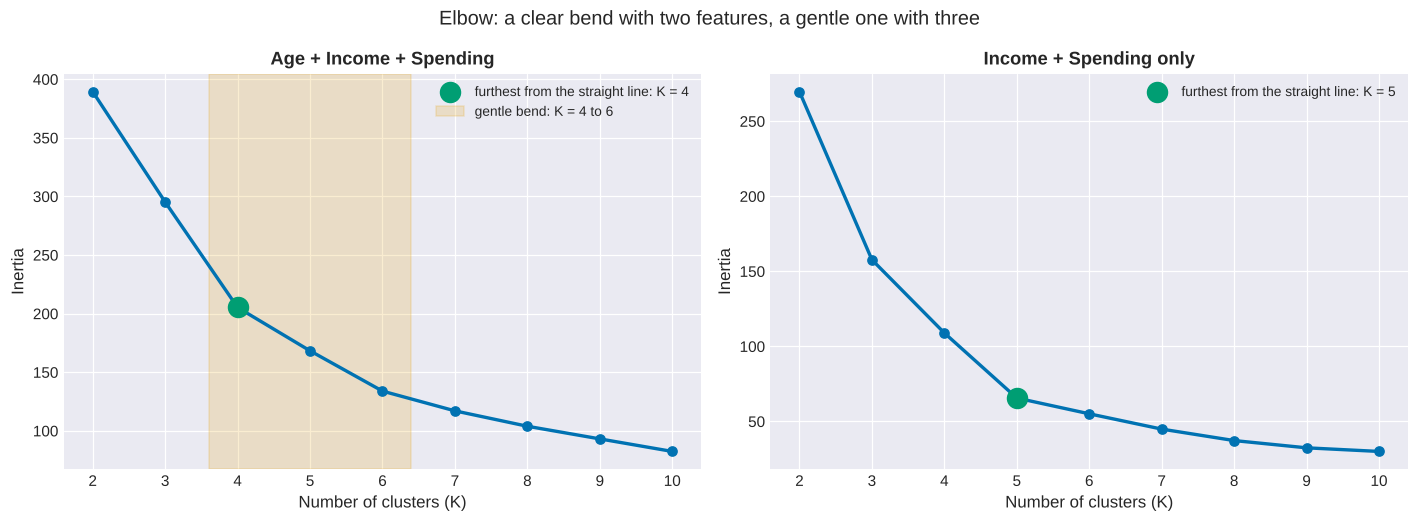

In [11]:
def chord_elbow(table):
    # The K whose point lies furthest below the straight line from the first to the last point
    x = (table["K"] - table["K"].min()) / (table["K"].max() - table["K"].min())
    y = (table["inertia"] - table["inertia"].min()) / (table["inertia"].max() - table["inertia"].min())
    return int(table["K"].iloc[((1 - x) - y).argmax()])

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
for ax, (name, table) in zip(axes, elbow.items()):
    ax.plot(table["K"], table["inertia"], marker="o", color=BLUE, linewidth=2.2)
    k_chord = chord_elbow(table)
    ax.scatter([k_chord], [table.loc[table["K"] == k_chord, "inertia"].iloc[0]], s=170, color=GREEN, zorder=5,
               label=f"furthest from the straight line: K = {k_chord}")
    if name.startswith("Age"):
        ax.axvspan(3.6, 6.4, color=GOLD, alpha=0.18, label="gentle bend: K = 4 to 6")
    ax.set_xticks(K_RANGE)
    ax.set_xlabel("Number of clusters (K)")
    ax.set_ylabel("Inertia")
    ax.set_title(name.split(" (")[0], fontsize=12)
    ax.legend(fontsize=9)
plt.suptitle("Elbow: a clear bend with two features, a gentle one with three", fontsize=13)
plt.tight_layout()
plt.savefig("images/elbow_curves.png")
plt.show()

- **Income + Spending only:** a clear elbow at K = 5. Inertia falls 40% going from 4 to 5 clusters, and only 16% from 5 to 6
- **All three columns:** no sharp elbow. The drops are 30% (3 to 4), 18% (4 to 5), 20% (5 to 6), then 13% or less. The bend is somewhere between K = 4 and K = 6
- The elbow is a visual judgment, so the next section checks it another way

## 7. Cross-check: silhouette score and random starts

In [12]:
def silhouette_by_k(X):
    return {k: silhouette_score(X, KMeans(n_clusters=k, init="k-means++", n_init=10, random_state=42).fit_predict(X))
            for k in K_RANGE}

sil = {}
for name, cols in feature_sets.items():
    X_set, _ = scale_numeric(df, cols)
    sil[name] = silhouette_by_k(X_set)

sil_table = pd.DataFrame({name.split(" (")[0]: s for name, s in sil.items()})
sil_table.index.name = "K"
print(sil_table.round(3).to_string())
for name, s in sil.items():
    best = max(s, key=s.get)
    print(f"\n{name.split(' (')[0]}: highest silhouette at K = {best} ({s[best]:.3f})")

    Age + Income + Spending  Income + Spending only
K                                                  
2                     0.335                   0.321
3                     0.358                   0.467
4                     0.404                   0.494
5                     0.417                   0.555
6                     0.428                   0.540
7                     0.417                   0.528
8                     0.408                   0.455
9                     0.418                   0.457
10                    0.407                   0.443

Age + Income + Spending: highest silhouette at K = 6 (0.428)

Income + Spending only: highest silhouette at K = 5 (0.555)


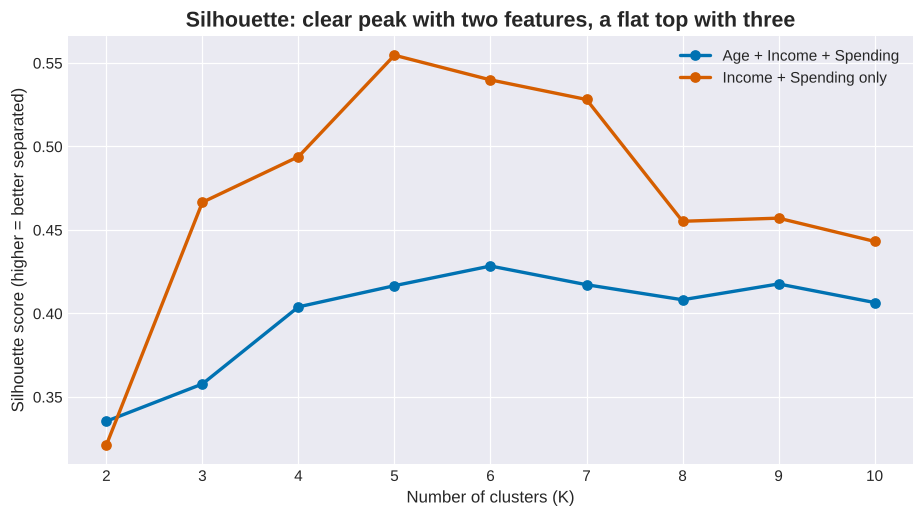

In [13]:
fig, ax = plt.subplots(figsize=(8.5, 4.8))
for (name, s), color in zip(sil.items(), [BLUE, ORANGE]):
    ax.plot(list(s.keys()), list(s.values()), marker="o", linewidth=2.2, color=color, label=name.split(" (")[0])
ax.set_xticks(K_RANGE)
ax.set_xlabel("Number of clusters (K)")
ax.set_ylabel("Silhouette score (higher = better separated)")
ax.set_title("Silhouette: clear peak with two features, a flat top with three")
ax.legend()
plt.tight_layout()
plt.savefig("images/silhouette_by_k.png")
plt.show()

In [14]:
# Why n_init matters: one random start can land on a poor solution (K = 5, all three columns)
X3, _ = scale_numeric(df, NUMERIC)
one_start = [KMeans(n_clusters=5, init="k-means++", n_init=1, random_state=s).fit(X3).inertia_ for s in range(20)]
ten_starts = [KMeans(n_clusters=5, init="k-means++", n_init=10, random_state=s).fit(X3).inertia_ for s in range(20)]

print("Inertia over 20 different random seeds, K = 5:")
print(f"  n_init = 1  : lowest {min(one_start):.1f} | highest {max(one_start):.1f}")
print(f"  n_init = 10 : lowest {min(ten_starts):.1f} | highest {max(ten_starts):.1f}")
print(f"  seeds where a single start was worse than the best solution: {sum(v > min(ten_starts) + 0.01 for v in one_start)} of 20")

Inertia over 20 different random seeds, K = 5:
  n_init = 1  : lowest 168.2 | highest 194.4
  n_init = 10 : lowest 168.2 | highest 168.2
  seeds where a single start was worse than the best solution: 9 of 20


- With **Income + Spending**, the silhouette peaks at K = 5 and K = 6 (0.555 vs 0.540), agreeing with the elbow
- With **all three columns**, the silhouette is flat: every K from 4 to 10 scores between 0.40 and 0.43, with the top at K = 6 (0.428). Silhouette does not settle it either
- A single random start often lands on a worse solution (inertia up to 194 instead of 168). With 10 starts the answer is stable. I use `n_init=10` and a fixed `random_state` from now on

## 8. Which K goes into Day 85?

In [15]:
# A last sanity check on K = 4, 5 and 6 with all three columns: are any clusters tiny?
for k in [4, 5, 6]:
    labels = KMeans(n_clusters=k, init="k-means++", n_init=10, random_state=42).fit_predict(X3)
    sizes = np.bincount(labels)
    print(f"K = {k}: cluster sizes {sorted(sizes.tolist(), reverse=True)} | smallest = {100 * sizes.min() / len(df):.0f}% of customers")

K = 4: cluster sizes [65, 57, 40, 38] | smallest = 19% of customers
K = 5: cluster sizes [54, 47, 40, 39, 20] | smallest = 10% of customers
K = 6: cluster sizes [45, 39, 39, 33, 23, 21] | smallest = 10% of customers


**Decision: carry K = 5 into Day 85, with K = 4 and K = 6 as side checks.** This is a judgment call, and I want to be clear about why:
- K = 5 is the clearest elbow on Income + Spending, and it is the middle of the K = 4 to 6 bend on all three columns
- No cluster is tiny at K = 5 (the smallest is 10% of customers)
- With all three columns the evidence is weak. The straight-line rule picks K = 4 on the full data, and K = 5 only comes out as its most common pick across resamples (16 of 30 against 11 for K = 4, see the Mini Challenge). So on Day 85 I will look at whether the K = 5 groups make sense, instead of treating K = 5 as proven

## Practice Exercise
Is `Gender` worth using? Compare the Spending Score of female and male customers: the difference in means, with a 95% bootstrap interval (resample each group 5,000 times).

In [16]:
rng = np.random.default_rng(42)
female = df.loc[df["Gender"] == "Female", "Spending"].to_numpy()
male = df.loc[df["Gender"] == "Male", "Spending"].to_numpy()

diffs = [rng.choice(female, len(female)).mean() - rng.choice(male, len(male)).mean() for _ in range(5000)]
low, high = np.percentile(diffs, [2.5, 97.5])
print(f"Mean spending score: female {female.mean():.1f} | male {male.mean():.1f} | difference {female.mean() - male.mean():+.1f}")
print(f"95% bootstrap interval for the difference: {low:+.1f} to {high:+.1f}")
print("The interval includes 0, so there is no clear spending gap between genders." if low < 0 < high
      else "The interval excludes 0, so there is a gap between genders.")

Mean spending score: female 51.5 | male 48.5 | difference +3.0
95% bootstrap interval for the difference: -4.3 to +10.4
The interval includes 0, so there is no clear spending gap between genders.


## Mini Challenge
How stable is the choice of K? Resample the 200 customers with replacement 30 times, redo the elbow each time with the "furthest from the straight line" rule, and count which K it picks. Do it for both feature sets.

In [17]:
rng = np.random.default_rng(42)

def pick_k(sample, cols):
    X_s, _ = scale_numeric(sample, cols)
    table = elbow_table(X_s)
    return chord_elbow(table)

picks = {}
for name, cols in feature_sets.items():
    picks[name.split(" (")[0]] = Counter(pick_k(df.iloc[rng.integers(0, len(df), len(df))], cols) for _ in range(30))

for name, counts in picks.items():
    print(f"{name}: " + ", ".join(f"K={k}: {counts[k]} of 30" for k in sorted(counts)))

Age + Income + Spending: K=4: 11 of 30, K=5: 16 of 30, K=6: 3 of 30
Income + Spending only: K=4: 1 of 30, K=5: 29 of 30


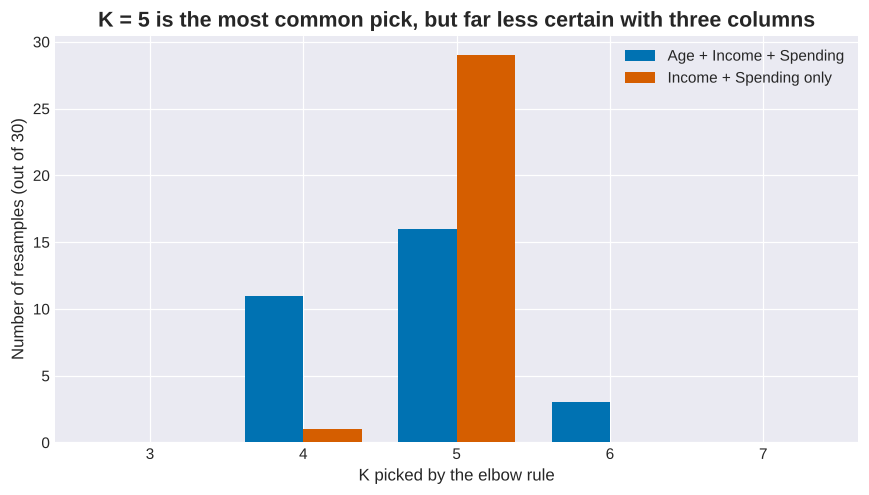

In [18]:
ks_shown = [3, 4, 5, 6, 7]
fig, ax = plt.subplots(figsize=(8, 4.6))
width = 0.38
for i, (name, counts) in enumerate(picks.items()):
    ax.bar(np.array(ks_shown) + (i - 0.5) * width, [counts.get(k, 0) for k in ks_shown], width,
           label=name, color=[BLUE, ORANGE][i])
ax.set_xticks(ks_shown)
ax.set_xlabel("K picked by the elbow rule")
ax.set_ylabel("Number of resamples (out of 30)")
ax.set_title("K = 5 is the most common pick, but far less certain with three columns")
ax.legend()
plt.tight_layout()
plt.savefig("images/k_choice_stability.png")
plt.show()

## Summary
- The Mall Customers data (200 customers) is clean: no missing values, no duplicates, believable ranges
- Age leans young, income is fairly symmetric with two 137k outliers, and spending is centered near 50 with wide tails. Age and Spending are moderately negatively related (r = -0.33). Gender does not separate anything
- `StandardScaler` puts the three columns on one scale. It changed the K = 5 groups noticeably (agreement 0.60), even though the raw spreads were already similar
- Elbow, K = 2 to 10: with Income + Spending the bend is clear at K = 5. With all three columns it is gentle (K = 4 to 6), and the silhouette is flat
- One random start can give a worse solution. `n_init=10` fixes that
- Decision: K = 5 goes into Day 85, with 4 and 6 as side checks. Across 30 resamples the elbow rule picked K = 5 in 16 of 30 with three columns, and 29 of 30 with two
- Next: Day 85, K-Means, PCA picture and cluster profiles